# IV Quality Monitor: a visual walkthrough

This notebook walks through the whole project on **real data**, one pipeline step at a time, with a table or chart for each step. Everything shown is read from the project's DuckDB database or produced by the project's own code. Nothing is typed in by hand.

**The one-sentence version:** option data from a vendor is full of stale, crossed and mispriced quotes. This project recomputes implied volatility itself, fits a smooth volatility surface, and flags quotes that don't fit or that break no-arbitrage rules.

| Step | What it does | Section |
|---|---|---|
| ingest | pull option chains into an untouched `raw_quotes` table | 1 |
| clean | flag bad quotes (never delete) | 2 |
| iv | compute our own implied vol, compare with the vendor's | 3 |
| forward | estimate the forward price per expiry | 4 |
| calibrate | fit an SVI smile per expiry | 5 |
| checks | arbitrage and outlier rules | 6 |
| ml | Isolation Forest anomaly layer | 7 |
| evaluate | inject known errors, measure detection | 8 |
| remediate | quarantine / correct / escalate, with an audit log | 9 |
| alert | thresholds on the daily metrics | 10 |

*How to read it:* run top to bottom. The notebook opens the database read-only and makes no network calls, so you can't damage anything.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ivmon import config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 95)
pd.set_option("display.float_format", "{:,.4g}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

con = duckdb.connect(str(config.DB_PATH), read_only=True)


def q(sql, params=None):
    """Run SQL, return a DataFrame."""
    return con.execute(sql, params or []).df()


def day(x):
    return str(pd.Timestamp(x).date())


# The latest snapshot that went through the whole pipeline.
SNAP = con.execute("SELECT max(snapshot_ts) FROM svi_params").fetchall()[0][0]
print("Snapshot analysed:", SNAP, "UTC")
print("Underlyings:", ", ".join(config.TICKERS))

Snapshot analysed: 2026-11-09 20:22:53 UTC
Underlyings: SPY, AAPL, NVDA, XOM, GLD, USO, SLV


## 1. The raw data

`raw_quotes` is exactly what the vendor (yfinance) sent, and no code ever modifies it. Every number later in the notebook can be traced back to a row here.

Each row is one option contract: an underlying, an expiry date, call or put, a strike, and a bid and ask price. yfinance only serves the *current* chain, so history only exists for the days we ran the pipeline.

,snapshot_ts,quotes,zero_bid_pct,wide_spread_pct
0,2026-11-09 10:51:52,5792,99.4,0.5007
1,2026-11-09 19:22:20,5792,18.51,28.12
2,2026-11-09 20:22:53,5792,19.94,29.51


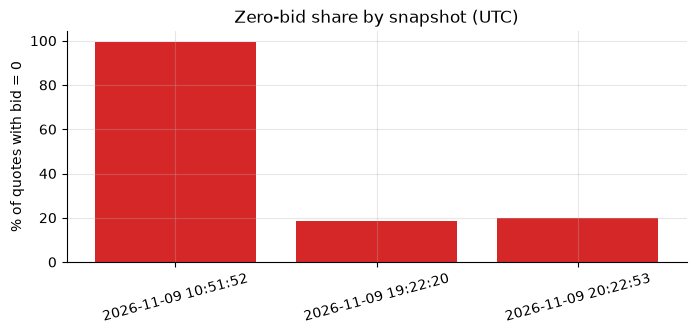

In [2]:
snaps = q("""
    SELECT snapshot_ts, count(*) AS quotes,
           100 * avg(zero_bid::INT)    AS zero_bid_pct,
           100 * avg(wide_spread::INT) AS wide_spread_pct
    FROM clean_quotes GROUP BY 1 ORDER BY 1""")
snaps["snapshot_ts"] = snaps["snapshot_ts"].astype(str)
display(snaps)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(snaps["snapshot_ts"], snaps["zero_bid_pct"], color="tab:red")
ax.set_ylabel("% of quotes with bid = 0")
ax.set_title("Zero-bid share by snapshot (UTC)")
plt.xticks(rotation=15)
plt.show()

**What to notice:** one snapshot was pulled *before* the US market opened, and almost every quote has bid = 0 and ask = 0 (nothing to trade against). That's why the pipeline has a zero-bid alert and why we analyse a market-hours snapshot.

In [3]:
coverage = q("""
    SELECT underlying, any_value(spot) AS spot, count(DISTINCT expiry) AS expiries,
           count(*) AS quotes, min(strike) AS min_strike, max(strike) AS max_strike
    FROM raw_quotes WHERE snapshot_ts = ? GROUP BY 1 ORDER BY quotes DESC""", [SNAP])
display(coverage)

print("A few raw SPY rows near the money, nearest expiry:")
spy_exp = q("SELECT min(expiry) e FROM raw_quotes WHERE snapshot_ts=? AND underlying='SPY'", [SNAP])["e"][0]
spot = coverage.set_index("underlying").loc["SPY", "spot"]
display(q("""
    SELECT underlying, expiry, option_type, strike, bid, ask, last, volume, open_interest, vendor_iv
    FROM raw_quotes WHERE snapshot_ts=? AND underlying='SPY' AND expiry=?
      AND abs(strike - ?) < 6 ORDER BY strike, option_type""", [SNAP, spy_exp, spot]).head(12))

,underlying,spot,expiries,quotes,min_strike,max_strike
0,SPY,755,6,1610,500,950
1,USO,141.5,6,943,5,330
2,GLD,380,6,904,205,600
3,NVDA,177.9,6,749,2.5,480
4,AAPL,351.1,6,650,100,600
5,SLV,48.23,6,593,14,110
6,XOM,164.1,6,343,50,260


A few raw SPY rows near the money, nearest expiry:


,underlying,expiry,option_type,strike,bid,ask,last,volume,open_interest,vendor_iv
0,SPY,2026-11-09,C,750,4.18,4.21,4.14,371388,9593,1e-05
1,SPY,2026-11-09,P,750,0.06,0.07,0.07,359975,3257,0.07862
2,SPY,2026-11-09,C,751,3.16,3.19,3.2,349413,2860,1e-05
3,SPY,2026-11-09,P,751,0.09,0.1,0.09,305900,536,0.07179
4,SPY,2026-11-09,C,752,2.24,2.25,2.24,465618,6081,1e-05
5,SPY,2026-11-09,P,752,0.16,0.17,0.17,447544,824,0.06715
6,SPY,2026-11-09,C,753,1.44,1.46,1.46,538350,3666,1e-05
7,SPY,2026-11-09,P,753,0.32,0.33,0.33,290101,628,0.06593
8,SPY,2026-11-09,C,754,0.8,0.81,0.8,411035,3006,1e-05
9,SPY,2026-11-09,P,754,0.68,0.69,0.69,164951,1061,0.07105


## 2. Cleaning: flag, don't delete

Cleaning adds quality flags and derived fields (mid price, bid-ask spread, time to expiry). Bad rows stay in the table so rules can disagree and a human can see the evidence.

| Flag | Meaning |
|---|---|
| `zero_bid` | no bid, so no real market on that side |
| `wide_spread` | spread is large relative to the mid price |
| `stale_trade` | last trade is old |
| `low_liquidity` | tiny volume and open interest |
| `crossed_market` | bid is above ask, which is impossible in a healthy market |

,zero_bid,wide_spread,stale_trade,low_liquidity,crossed_market
underlying,,,,,
AAPL,23.7,34.2,18.3,1.1,0
GLD,26.8,46.5,13.7,0.4,0
NVDA,21.2,27.4,12.7,1.5,0
SLV,23.8,31,17,0.2,0
SPY,17.1,23.2,10.2,6.1,0
USO,7.8,18.1,18.8,0.5,0
XOM,31.8,38.8,34.4,0.6,0


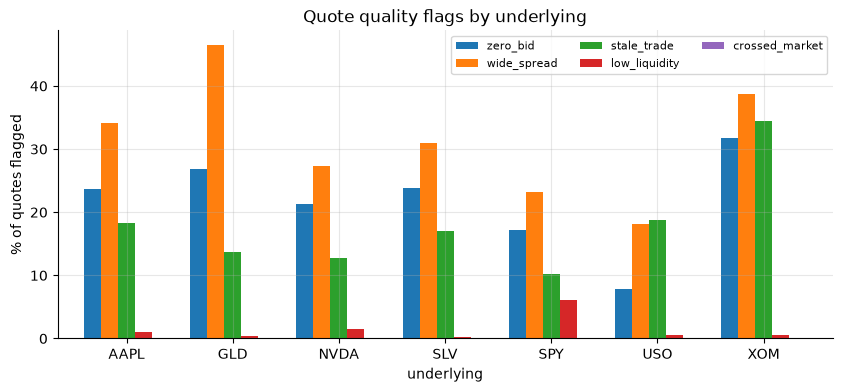

In [4]:
flags = q("""
    SELECT underlying,
           100 * avg(zero_bid::INT) AS zero_bid, 100 * avg(wide_spread::INT) AS wide_spread,
           100 * avg(stale_trade::INT) AS stale_trade, 100 * avg(low_liquidity::INT) AS low_liquidity,
           100 * avg(crossed_market::INT) AS crossed_market
    FROM clean_quotes WHERE snapshot_ts = ? GROUP BY 1 ORDER BY 1""", [SNAP]).set_index("underlying")
display(flags.round(1))

ax = flags.plot.bar(figsize=(10, 4), width=0.8)
ax.set_ylabel("% of quotes flagged")
ax.set_title("Quote quality flags by underlying")
ax.legend(ncol=3, fontsize=8)
plt.xticks(rotation=0)
plt.show()

**What to notice:** XOM has the most zero-bid and stale quotes, and GLD has the widest spreads, while SPY has the most low-liquidity flags. No quote is crossed, so the problems here are about *thin* markets rather than impossible prices.

## 3. Our own implied volatility vs the vendor's

**Implied volatility (IV)** is the volatility number that makes the Black-76 model price equal the market price. We invert the price with **Brent's method** (always converges, unlike Newton when vega is tiny). We only invert **out-of-the-money** options: they are mostly time value, so the early-exercise premium of American options (which the European model ignores) is small there.

When no IV exists, we store a *reason code* instead of failing silently.

,iv_reason,quotes,share_%
0,ok,2151,65.24
1,skipped_zero_bid,1146,34.76


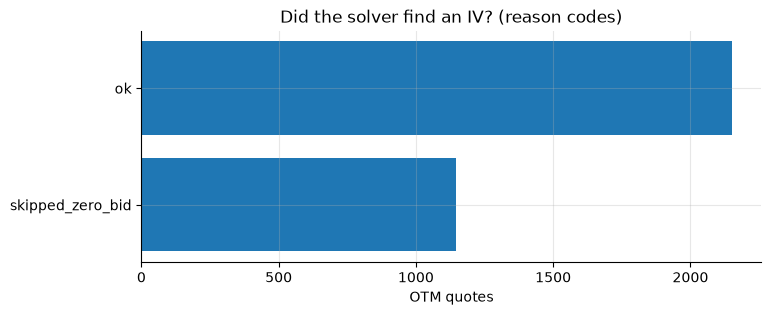

In [5]:
iv = q("SELECT * FROM iv_quotes WHERE snapshot_ts = ?", [SNAP])

reasons = iv["iv_reason"].value_counts().rename_axis("iv_reason").reset_index(name="quotes")
reasons["share_%"] = 100 * reasons["quotes"] / reasons["quotes"].sum()
display(reasons)

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(reasons["iv_reason"][::-1], reasons["quotes"][::-1], color="tab:blue")
ax.set_xlabel("OTM quotes")
ax.set_title("Did the solver find an IV? (reason codes)")
plt.show()

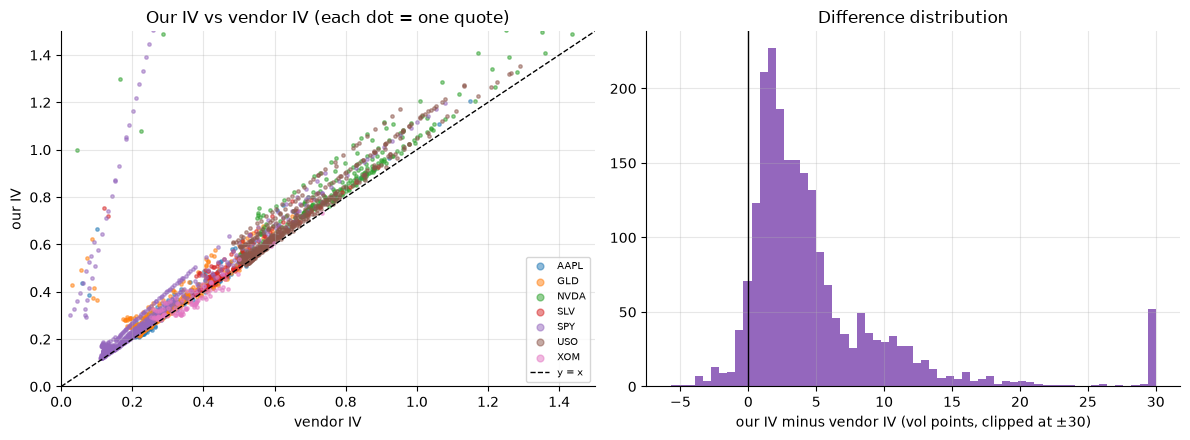

,quotes,median_diff_vp,median_abs_diff_vp
underlying,,,
AAPL,194,1.739,1.739
GLD,364,2.78,2.78
NVDA,265,5.173,5.173
SLV,171,2.411,2.411
SPY,586,3.099,3.099
USO,471,3.702,3.702
XOM,100,0.6596,2.268


In [6]:
solved = iv[iv["own_iv"].notna() & iv["vendor_iv"].between(0.01, 3)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, g in solved.groupby("underlying"):
    axes[0].scatter(g["vendor_iv"], g["own_iv"], s=6, alpha=0.5, label=name)
lim = [0, min(1.5, solved[["vendor_iv", "own_iv"]].max().max())]
axes[0].plot(lim, lim, "k--", lw=1, label="y = x")
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("vendor IV"); axes[0].set_ylabel("our IV")
axes[0].set_title("Our IV vs vendor IV (each dot = one quote)")
axes[0].legend(fontsize=7, markerscale=2)

axes[1].hist(solved["iv_diff"].clip(-0.3, 0.3) * 100, bins=60, color="tab:purple")
axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("our IV minus vendor IV (vol points, clipped at ±30)")
axes[1].set_title("Difference distribution")
plt.tight_layout()
plt.show()

diff = solved.groupby("underlying")["iv_diff"].agg(
    quotes="count", median_diff_vp=lambda s: 100 * s.median(),
    median_abs_diff_vp=lambda s: 100 * s.abs().median())
display(diff)

**Why they differ:** the vendor uses its own forward, rate, dividend and (for American options) a different model, and it sometimes computes IV from stale last prices. We use bid-ask **mid** prices and a parity-implied forward. Points far from the diagonal are exactly the quotes worth a second look.

## 4. Forward price per expiry

An option's price depends on the **forward** `F` (what the underlying is worth at expiry, including carry), not on spot. We get `F` from **put-call parity**: `F = K + e^{rT}(C - P)`, taking the median over the 5 strikes closest to the money so one bad quote can't move it. If parity can't be computed, we fall back to spot and record that in `forward_method`.

,forward_method,expiries
0,parity,42


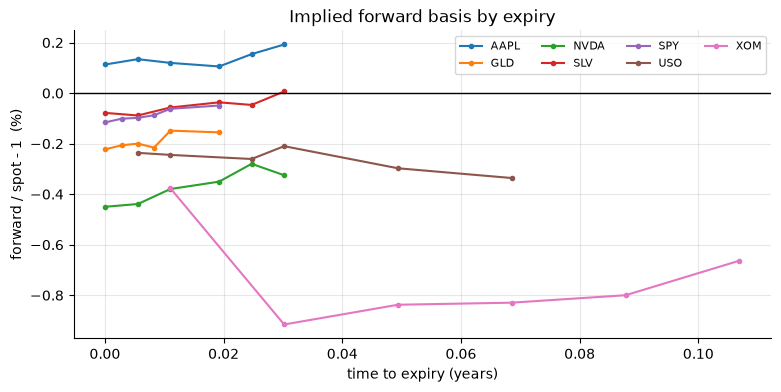

In [7]:
fwd = (iv.groupby(["underlying", "expiry"])
         .agg(forward=("forward", "first"), spot=("spot", "first"),
              method=("forward_method", "first"), tte=("tte_years", "first"))
         .reset_index())
fwd["basis_%"] = 100 * (fwd["forward"] / fwd["spot"] - 1)

display(fwd["method"].value_counts().rename_axis("forward_method").reset_index(name="expiries"))

fig, ax = plt.subplots(figsize=(9, 4))
for name, g in fwd.groupby("underlying"):
    g = g.sort_values("tte")
    ax.plot(g["tte"], g["basis_%"], marker="o", ms=3, label=name)
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("time to expiry (years)")
ax.set_ylabel("forward / spot - 1  (%)")
ax.set_title("Implied forward basis by expiry")
ax.legend(fontsize=8, ncol=4)
plt.show()

**What to notice:** the basis is small (within about 1% of spot), because all expiries here are within weeks. Its sign and size reflect rates, dividends and borrow costs, and also noise. A sudden jump within one underlying (XOM's second expiry is an example) can mean noisy parity quotes or a dividend falling between two expiries; the chart can't tell which.

## 5. Fitting the volatility surface (SVI)

Implied vol varies by strike, forming a **smile**. We fit one smile per expiry with the **raw SVI** curve for *total variance* `w = IV² × T`:

`w(k) = a + b · ( ρ·(k − m) + sqrt((k − m)² + σ²) )`, with `k = ln(K/F)` (log-moneyness).

| Parameter | What it controls |
|---|---|
| `a` | overall level (vertical shift) |
| `b` | how steep the wings are |
| `ρ` | skew (tilt left or right) |
| `m` | horizontal shift of the smile's minimum |
| `σ` | how rounded the bottom is |

The fit is robust (`soft_l1` loss, so one bad quote can't drag the curve) and weights tight-spread quotes more. Expiries with too few points are skipped and logged.

In [8]:
fits_all = q("SELECT * FROM svi_params WHERE snapshot_ts = ?", [SNAP])
display(fits_all["fit_status"].value_counts().rename_axis("fit_status").reset_index(name="expiries"))

fits = fits_all[fits_all["fit_status"] == "ok"].copy()
fits["rmse_vp"] = fits["rmse"] * 100
display(fits.groupby("underlying").agg(
    expiries_fit=("expiry", "count"), median_rmse_vp=("rmse_vp", "median"),
    worst_rmse_vp=("rmse_vp", "max"), median_points=("n_points", "median")))

print("Example fitted parameters (SPY):")
display(fits[fits["underlying"] == "SPY"][["expiry", "a", "b", "rho", "m", "sigma", "rmse_vp", "n_points"]])

,fit_status,expiries
0,ok,38
1,too_few_points,4


,expiries_fit,median_rmse_vp,worst_rmse_vp,median_points
underlying,,,,
AAPL,5,0.8047,1.637,38
GLD,5,0.9653,1.058,71
NVDA,5,1.688,2.021,55
SLV,5,1.027,1.66,34
SPY,6,1.205,5.379,99.5
USO,6,1.328,2.154,80.5
XOM,6,0.9552,1.954,14.5


Example fitted parameters (SPY):


,expiry,a,b,rho,m,sigma,rmse_vp,n_points
24,2026-11-09,-0.0001954,0.008541,-0.5412,-0.0159,0.02818,5.379,40
25,2026-11-10,-0.0008849,0.01488,-0.6335,-0.04391,0.08341,0.9982,80
26,2026-11-11,-0.004501,0.03162,-0.5479,-0.07974,0.1743,0.5821,97
27,2026-11-12,-0.002323,0.02666,-0.7242,-0.08137,0.1328,0.4961,102
28,2026-11-13,-0.006101,0.03896,-0.5159,-0.0743,0.1896,1.412,129
29,2026-11-16,-0.003095,0.03302,-0.7152,-0.08334,0.1445,1.728,138


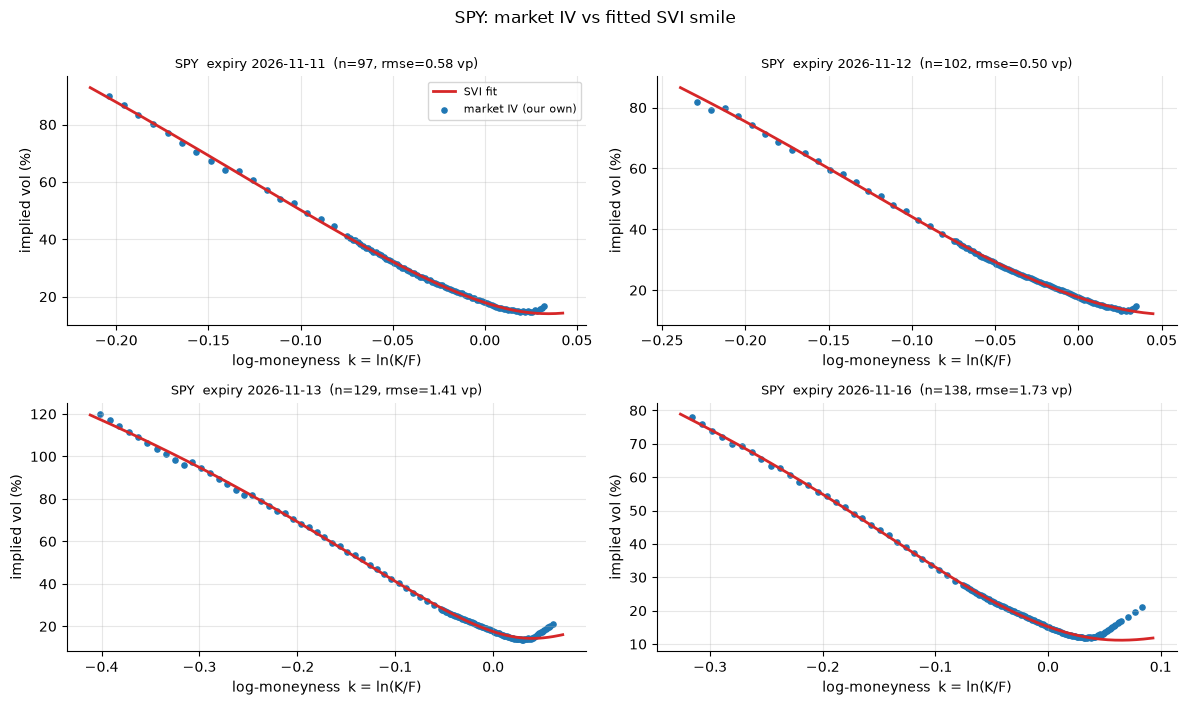

In [9]:
resid_all = q("SELECT * FROM svi_residuals WHERE snapshot_ts = ?", [SNAP])


def svi_w(k, p):
    return p["a"] + p["b"] * (p["rho"] * (k - p["m"]) + np.sqrt((k - p["m"]) ** 2 + p["sigma"] ** 2))


def plot_smile(ax, und, expiry, highlight_strikes=()):
    pts = resid_all[(resid_all["underlying"] == und) & (resid_all["expiry"] == expiry)]
    p = fits[(fits["underlying"] == und) & (fits["expiry"] == expiry)].iloc[0]
    T = pts["tte_years"].iloc[0]
    k = np.linspace(pts["log_moneyness"].min() - 0.01, pts["log_moneyness"].max() + 0.01, 200)
    ax.plot(k, np.sqrt(svi_w(k, p) / T) * 100, color="tab:red", lw=2, label="SVI fit")
    ax.scatter(pts["log_moneyness"], pts["own_iv"] * 100, s=14, color="tab:blue", label="market IV (our own)")
    hl = pts[pts["strike"].isin(highlight_strikes)]
    if len(hl):
        ax.scatter(hl["log_moneyness"], hl["own_iv"] * 100, s=90, facecolors="none",
                   edgecolors="black", lw=1.5, label="flagged outlier")
    ax.set_title(f"{und}  expiry {day(expiry)}  (n={len(pts)}, rmse={p['rmse_vp']:.2f} vp)", fontsize=9)
    ax.set_xlabel("log-moneyness  k = ln(K/F)")
    ax.set_ylabel("implied vol (%)")


def smile_grid(und, n=4):
    sel = fits[(fits["underlying"] == und)].sort_values("n_points", ascending=False).head(n).sort_values("expiry")
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, exp in zip(axes.ravel(), sel["expiry"]):
        plot_smile(ax, und, exp)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{und}: market IV vs fitted SVI smile", y=1.0)
    plt.tight_layout()
    plt.show()


smile_grid("SPY")

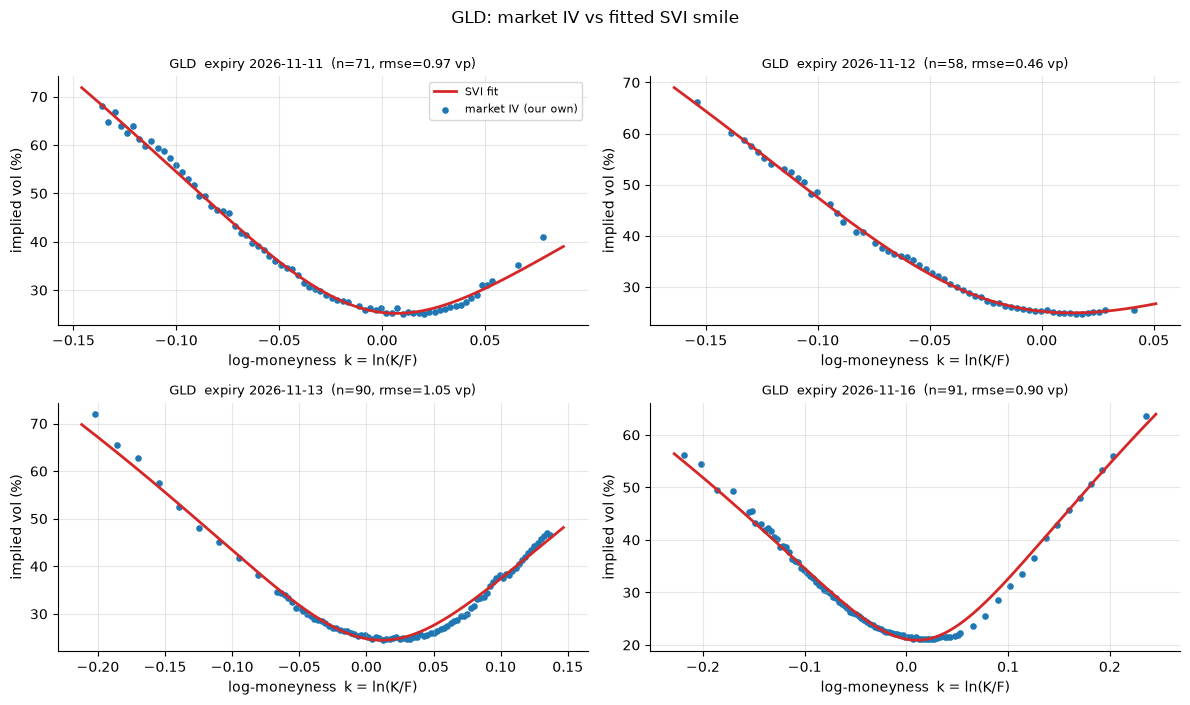

In [10]:
smile_grid("GLD")

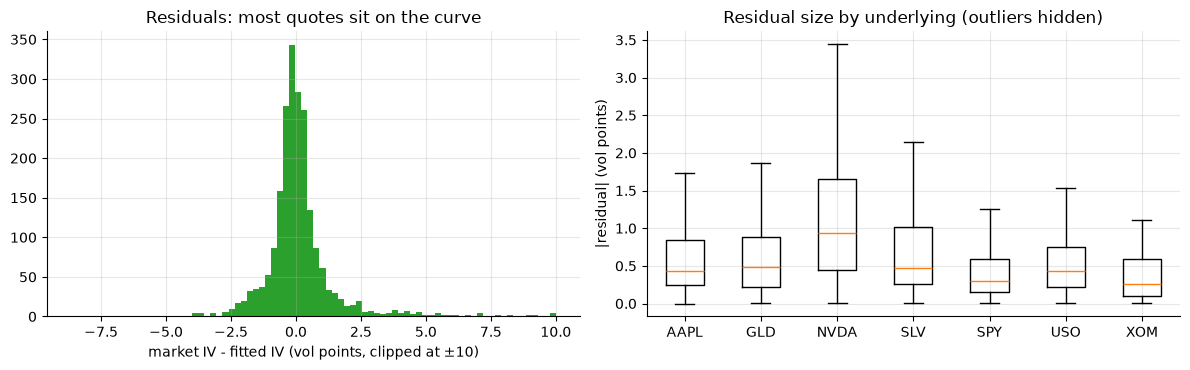

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(resid_all["resid_iv"].clip(-0.1, 0.1) * 100, bins=80, color="tab:green")
axes[0].set_xlabel("market IV - fitted IV (vol points, clipped at ±10)")
axes[0].set_title("Residuals: most quotes sit on the curve")
by_u = [g["resid_iv"].abs().mul(100).values for _, g in resid_all.groupby("underlying")]
axes[1].boxplot(by_u, tick_labels=sorted(resid_all["underlying"].unique()), showfliers=False)
axes[1].set_ylabel("|residual| (vol points)")
axes[1].set_title("Residual size by underlying (outliers hidden)")
plt.tight_layout()
plt.show()

**What to notice:** the residuals pile up near zero with fat tails. The fat tails are the quotes the next step flags. Fit error of about 1 vol point is typical for free data, since SVI can't be perfect when quotes are noisy.

## 6. Rule-based checks

Each rule returns flagged rows with a reason code and a severity, all stored in the `anomalies` table.

| Rule | In plain language |
|---|---|
| `butterfly_arbitrage` | the implied probability density went negative: a butterfly spread would have a negative price (Gatheral's `g(k) ≥ 0` test) |
| `calendar_arbitrage` | at the same moneyness, a longer-dated option has *less* total variance than a shorter one |
| `put_call_parity` | call minus put doesn't match the forward, beyond what the bid-ask spreads allow |
| `residual_outlier` | the quote sits far from the fitted curve (robust MAD-based z-score) |
| `param_stability` | today's curve moved a lot vs the previous snapshot (compared as curves) |

severity,high,medium,low,total
rule,,,,
butterfly_arbitrage,0,11,0,11
calendar_arbitrage,1,7,1,9
param_stability,1,5,0,6
put_call_parity,2,8,14,24
residual_outlier,16,45,80,141


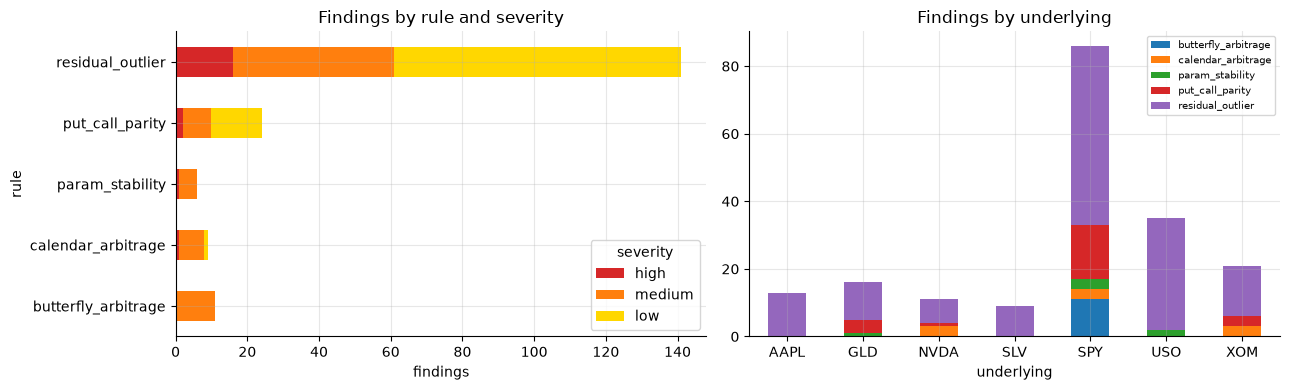

In [12]:
an = q("""SELECT * FROM anomalies WHERE snapshot_ts = ? AND NOT is_synthetic
          AND rule <> 'ml_isolation_forest'""", [SNAP])
sev = ["high", "medium", "low"]
piv = (an.pivot_table(index="rule", columns="severity", values="underlying", aggfunc="count", fill_value=0)
         .reindex(columns=sev, fill_value=0))
piv["total"] = piv.sum(axis=1)
display(piv)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
piv[sev].plot.barh(stacked=True, ax=axes[0], color=["tab:red", "tab:orange", "gold"])
axes[0].set_title("Findings by rule and severity")
axes[0].set_xlabel("findings")
by_und = an.pivot_table(index="underlying", columns="rule", values="severity", aggfunc="count", fill_value=0)
by_und.plot.bar(stacked=True, ax=axes[1])
axes[1].set_title("Findings by underlying")
axes[1].legend(fontsize=7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
rank = {"high": 0, "medium": 1, "low": 2}
top = an.assign(r=an["severity"].map(rank)).sort_values(["r", "underlying", "expiry"]).head(12)
display(top[["underlying", "expiry", "strike", "option_type", "rule", "severity", "details"]].reset_index(drop=True))

,underlying,expiry,strike,option_type,rule,severity,details
0,GLD,2026-11-13,417,NaN,put_call_parity,high,"C-P-D(F-K) = -6.632 vs tolerance 1.237 (call mid 0.03, put mid 44.25)"
1,GLD,2026-11-13,416,NaN,put_call_parity,high,"C-P-D(F-K) = -6.632 vs tolerance 1.237 (call mid 0.03, put mid 43.25)"
2,NVDA,2026-11-18,120,P,residual_outlier,high,"IV 1.128 vs fit 1.065 (resid +6.29 vol pts, robust z=+11.1)"
3,SPY,2026-11-09,NaN,NaN,param_stability,high,"smile moved 61.4 vol pts RMS vs previous snapshot (a -0.001->-0.000, b 0.014->0.009, rho -0..."
4,SPY,2026-11-10,776,C,residual_outlier,high,"IV 0.211 vs fit 0.164 (resid +4.67 vol pts, robust z=+11.8)"
5,SPY,2026-11-16,800,C,residual_outlier,high,"IV 0.153 vs fit 0.112 (resid +4.13 vol pts, robust z=+10.3)"
6,SPY,2026-11-16,820,C,residual_outlier,high,"IV 0.210 vs fit 0.114 (resid +9.60 vol pts, robust z=+24.1)"
7,SPY,2026-11-16,810,C,residual_outlier,high,"IV 0.182 vs fit 0.112 (resid +7.03 vol pts, robust z=+17.6)"
8,SPY,2026-11-16,804,C,residual_outlier,high,"IV 0.165 vs fit 0.112 (resid +5.33 vol pts, robust z=+13.3)"
9,SPY,2026-11-16,805,C,residual_outlier,high,"IV 0.168 vs fit 0.112 (resid +5.62 vol pts, robust z=+14.0)"


### A residual outlier, visually

Here is the SPY expiry with the most flagged residual outliers. Circled points are quotes the rule flagged: they sit away from the red SVI curve while their neighbours sit on it.

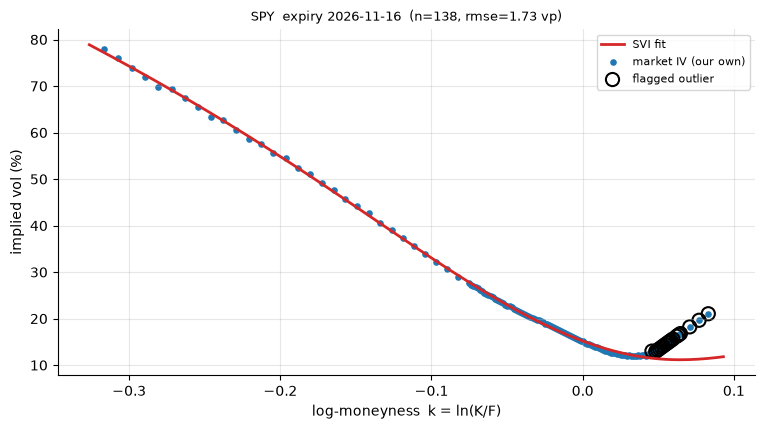

In [14]:
ro = an[(an["rule"] == "residual_outlier") & (an["underlying"] == "SPY")]
if ro.empty:
    print("No SPY residual outliers in this snapshot.")
else:
    exp = ro["expiry"].value_counts().index[0]
    flagged = set(ro[ro["expiry"] == exp]["strike"])
    if exp in set(fits[fits["underlying"] == "SPY"]["expiry"]):
        fig, ax = plt.subplots(figsize=(9, 4.5))
        plot_smile(ax, "SPY", exp, flagged)
        ax.legend(fontsize=8)
        plt.show()

### Calendar consistency, visually

Total variance at the money, `w(k=0)`, should *never decrease* as expiry gets longer (more time can't make the stock less uncertain). Red crosses would mark expiries where it drops versus the previous expiry. At the money every underlying is increasing here, so the calendar findings in the table above come from other moneyness levels, where the check compares curves away from the money.

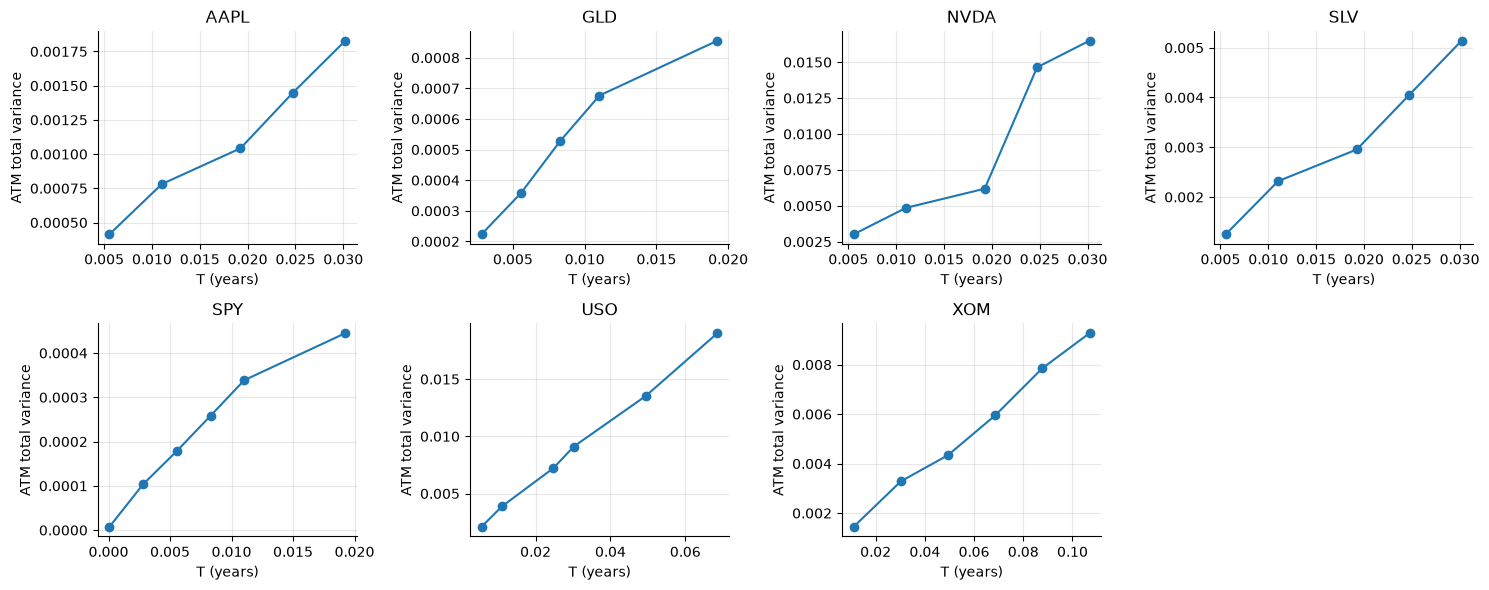

In [15]:
T = resid_all.groupby(["underlying", "expiry"])["tte_years"].mean().rename("T").reset_index()
f = fits.merge(T, on=["underlying", "expiry"])
f["w_atm"] = svi_w(0.0, f)

names = sorted(f["underlying"].unique())
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, name in zip(axes.ravel(), names):
    g = f[f["underlying"] == name].sort_values("T")
    ax.plot(g["T"], g["w_atm"], marker="o", color="tab:blue")
    drops = g[g["w_atm"].diff() < 0]
    ax.scatter(drops["T"], drops["w_atm"], marker="x", s=80, color="red", zorder=5)
    ax.set_title(name)
    ax.set_xlabel("T (years)")
    ax.set_ylabel("ATM total variance")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. The ML layer (Isolation Forest)

An **Isolation Forest** is unsupervised: it has no labels, it just isolates points that look unusual in a feature space (SVI residual, relative spread, log-moneyness, time to expiry, volume / open interest, vendor-vs-own IV gap). Its **contamination** setting (5%) fixes roughly how many points it flags, so the flag *rate* is a setting, not a result.

In [16]:
ml = q("""SELECT * FROM anomalies WHERE snapshot_ts = ? AND NOT is_synthetic
          AND rule = 'ml_isolation_forest'""", [SNAP])
print(f"ML flagged {len(ml)} quotes (contamination setting: {config.ML_CONTAMINATION:.0%}).")
display(ml.groupby(["underlying", "severity"]).size().unstack(fill_value=0))

expiring_today = (ml["expiry"].dt.date == pd.Timestamp(SNAP).date()).mean()
same_day_all = con.execute(
    "SELECT avg((expiry = CAST(snapshot_ts AS DATE))::INT) FROM iv_quotes WHERE snapshot_ts = ?", [SNAP]
).fetchall()[0][0]
print(f"Share of ML flags on options expiring on the snapshot day: {expiring_today:.0%} "
      f"(those options are {same_day_all:.0%} of all OTM quotes)")
display(ml.sort_values("severity").head(6)[["underlying", "expiry", "strike", "option_type", "severity", "details"]])

ML flagged 107 quotes (contamination setting: 5%).


severity,high,low,medium
underlying,,,
AAPL,0,7,0
GLD,0,3,0
NVDA,0,5,1
SLV,0,2,0
SPY,21,12,19
USO,0,15,7
XOM,1,9,5


Share of ML flags on options expiring on the snapshot day: 37% (those options are 12% of all OTM quotes)


,underlying,expiry,strike,option_type,severity,details
28,SPY,2026-11-09,725,P,high,"isolation score 0.669 (rel_resid -0.00, rel_spread 0.67, k -0.039)"
22,SPY,2026-11-09,761,C,high,"isolation score 0.702 (rel_resid +0.35, rel_spread 0.40, k +0.009)"
24,SPY,2026-11-09,760,C,high,"isolation score 0.713 (rel_resid +0.33, rel_spread 0.29, k +0.008)"
26,SPY,2026-11-09,758,C,high,"isolation score 0.682 (rel_resid +0.19, rel_spread 0.15, k +0.005)"
27,SPY,2026-11-09,722,P,high,"isolation score 0.682 (rel_resid +0.00, rel_spread 0.67, k -0.044)"
57,SPY,2026-11-09,744,P,high,"isolation score 0.674 (rel_resid +0.05, rel_spread 0.40, k -0.014)"


**What to notice (an honest finding):** compare the two percentages above. The ML layer flags same-day-expiry options far more often than their share of quotes. There the bid-ask spread is naturally huge, and several of the top flags have almost no SVI residual and just a wide spread. That's "wide spread near expiry", not a mispricing, so this layer is weak on its own. Section 8 measures that properly.

## 8. How good is detection? (synthetic injection)

We can't know which real quotes are wrong. So we **copy a real snapshot, inject known corruptions** (price spikes, stale quotes, swapped bid/ask, strike typos, shifted IV), run the full pipeline on the copy, and measure what gets caught. The copy lives in a separate in-memory database, so real data is never touched.

- **Precision**: of the quotes we flagged, how many were truly injected.
- **Recall**: of the injected quotes, how many we caught.

*Caveat:* the corruptions are our own, so this measures sensitivity to those error types, not to real vendor errors. (This cell takes about 20 to 30 seconds.) The ML row can differ by a quote or two from `python -m ivmon.synthetic` (this copy is built in memory, which may change row order; I did not verify that is the cause), so treat small ML differences as noise.

In [17]:
import logging
logging.disable(logging.WARNING)  # hide the per-expiry "SVI skipped" log lines

from ivmon.synthetic import build_baseline, build_synthetic, evaluate

syn_con, truth = build_synthetic(con, SNAP, db_path=":memory:")
base_con = build_baseline(con, SNAP)
res = evaluate(syn_con, base_con, SNAP)

print(f"{len(truth)} corruptions injected (seed {config.SYNTH_SEED}).")
display(truth.groupby("injection_type").size().rename("n_injected").reset_index())
display(res["summary"].round(3))

119 corruptions injected (seed 7).


,injection_type,n_injected
0,iv_shift,25
1,price_spike,25
2,stale_quote,25
3,strike_typo,19
4,swapped_bid_ask,25


,detector,flagged,TP,FP,FN,TN,precision,recall,flagged_without_injection
0,rule_based,346,87,259,32,5414,0.251,0.731,201
1,ml,105,14,91,105,5582,0.133,0.118,107
2,combined,393,94,299,25,5374,0.239,0.79,241


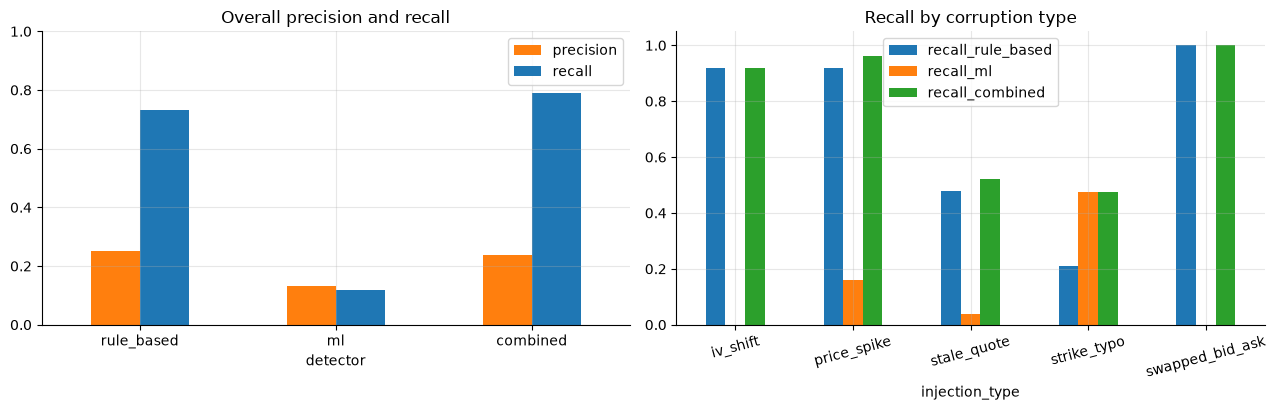

,n_injected,recall_rule_based,recall_ml,recall_combined
injection_type,,,,
iv_shift,25,0.92,0,0.92
price_spike,25,0.92,0.16,0.96
stale_quote,25,0.48,0.04,0.52
strike_typo,19,0.21,0.47,0.47
swapped_bid_ask,25,1,0,1


In [18]:
summ = res["summary"].set_index("detector")
byt = res["recall_by_type"].set_index("injection_type")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
summ[["precision", "recall"]].plot.bar(ax=axes[0], color=["tab:orange", "tab:blue"])
axes[0].set_title("Overall precision and recall")
axes[0].set_ylim(0, 1)
plt.setp(axes[0].get_xticklabels(), rotation=0)

byt[["recall_rule_based", "recall_ml", "recall_combined"]].plot.bar(ax=axes[1])
axes[1].set_title("Recall by corruption type")
axes[1].set_ylim(0, 1.05)
plt.setp(axes[1].get_xticklabels(), rotation=15)
plt.tight_layout()
plt.show()
display(byt.round(2))

**What to notice:**
- The rules are strong on swapped bid/ask, price spikes and IV shifts, and weaker on stale quotes and strike typos.
- The ML layer adds little overall; its one clear contribution is strike typos, where the rules are weakest.
- Precision is lowish mainly because real quotes already produce findings with no injection (`flagged_without_injection` in the table).

## 9. Remediation and the audit trail

Each finding maps to an action by an explicit policy in config:

- **quarantine**: exclude the quote from the surface;
- **correct**: replace it with the fitted-surface value, clearly marked;
- **escalate**: needs a human or quant (also the default for anything unlisted).

Every action is **appended** to `remediation_log` with before/after values and the triggering rule, and raw data is never changed. A `curated_quotes` view applies the actions on top of the raw layer.

,run_id,run_ts,snapshot_ts,is_synthetic,n_findings,n_actions
0,5,2026-11-09 20:31:18,2026-11-09 20:22:53,False,298,110


,action,rule,n
0,correct,residual_outlier,16
1,escalate,butterfly_arbitrage,3
2,escalate,butterfly_arbitrage; ml_isolation_forest,8
3,escalate,calendar_arbitrage,8
4,escalate,ml_isolation_forest,14
5,escalate,param_stability,6
6,escalate,put_call_parity,10
7,quarantine,residual_outlier,45


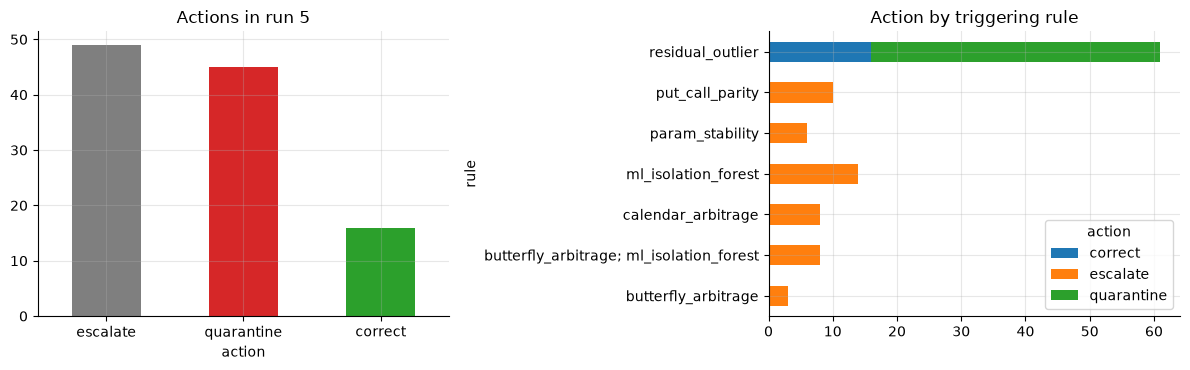

Sample audit-log rows (corrected quotes show a before and after value):


,underlying,expiry,strike,option_type,action,rule,severity,before_mid,after_mid,reason
15,SPY,2026-11-16,800,C,correct,residual_outlier,high,0.015,0.0002433,"IV 0.153 vs fit 0.112 (resid +4.13 vol pts, robust z=+10.3) [policy: residual_outlier/high ..."
17,SPY,2026-11-16,801,C,correct,residual_outlier,high,0.015,0.0001695,"IV 0.156 vs fit 0.112 (resid +4.44 vol pts, robust z=+11.0) [policy: residual_outlier/high ..."
37,NVDA,2026-11-18,120,P,correct,residual_outlier,high,0.125,0.08092,"IV 1.128 vs fit 1.065 (resid +6.29 vol pts, robust z=+11.1) [policy: residual_outlier/high ..."
52,SPY,2026-11-10,776,C,correct,residual_outlier,high,0.015,0.0009643,"IV 0.211 vs fit 0.164 (resid +4.67 vol pts, robust z=+11.8) [policy: residual_outlier/high ..."
62,SPY,2026-11-16,820,C,correct,residual_outlier,high,0.015,1.884e-07,"IV 0.210 vs fit 0.114 (resid +9.60 vol pts, robust z=+24.1) [policy: residual_outlier/high ..."


,underlying,expiry,strike,option_type,action,rule,severity,before_mid,after_mid,reason
11,NVDA,2026-11-16,120,P,quarantine,residual_outlier,medium,0.04,NaN,"IV 1.108 vs fit 1.019 (resid +8.95 vol pts, robust z=+7.1) [policy: residual_outlier/medium..."
32,AAPL,2026-11-11,375,C,quarantine,residual_outlier,medium,0.02,NaN,"IV 0.349 vs fit 0.292 (resid +5.77 vol pts, robust z=+8.4) [policy: residual_outlier/medium..."
33,AAPL,2026-11-11,305,P,quarantine,residual_outlier,medium,0.03,NaN,"IV 0.744 vs fit 0.699 (resid +4.55 vol pts, robust z=+6.6) [policy: residual_outlier/medium..."


In [19]:
run = q("""SELECT * FROM remediation_runs WHERE snapshot_ts = ? AND NOT is_synthetic
           ORDER BY run_id DESC LIMIT 1""", [SNAP])
display(run)
run_id = int(run["run_id"][0])

log = q("SELECT * FROM remediation_log WHERE run_id = ?", [run_id])
acts = log.groupby(["action", "rule"]).size().rename("n").reset_index()
display(acts)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
log["action"].value_counts().plot.bar(ax=axes[0], color=["tab:gray", "tab:red", "tab:green"][:log["action"].nunique()])
axes[0].set_title(f"Actions in run {run_id}")
plt.setp(axes[0].get_xticklabels(), rotation=0)
log.groupby(["rule", "action"]).size().unstack(fill_value=0).plot.barh(stacked=True, ax=axes[1])
axes[1].set_title("Action by triggering rule")
plt.tight_layout()
plt.show()

print("Sample audit-log rows (corrected quotes show a before and after value):")
cols = ["underlying", "expiry", "strike", "option_type", "action", "rule", "severity",
        "before_mid", "after_mid", "reason"]
display(log[log["action"] == "correct"][cols].head(5))
display(log[log["action"] == "quarantine"][cols].head(3))

In [20]:
n_raw = con.execute("SELECT count(*) FROM raw_quotes WHERE snapshot_ts = ?", [SNAP]).fetchall()[0][0]
n_cur = con.execute("SELECT count(*) FROM curated_quotes WHERE snapshot_ts = ?", [SNAP]).fetchall()[0][0]
print(f"raw_quotes rows: {n_raw}   curated_quotes rows: {n_cur}   (raw is never changed)")

from ivmon.remediate import compare_fit
cmp = compare_fit(con, SNAP)
print("Does the refit improve? (RMSE on one common set of untouched quotes, lower = better):")
display(pd.DataFrame([cmp["overall"]]))

raw_quotes rows: 5792   curated_quotes rows: 5792   (raw is never changed)
Does the refit improve? (RMSE on one common set of untouched quotes, lower = better):


,n_quotes,n_expiries,rmse_before,rmse_after
0,2034,37,0.9884,1.03


**What to notice (another honest finding):** refitting after remediation does *not* improve fit quality on the common set of untouched quotes, so the quarantine/correct policy for residual outliers isn't validated. This is why unlisted cases default to *escalate*, and why it's listed as a limitation.

## 10. Daily metrics and alerts

The last pipeline step turns the day into a few headline metrics and compares them to thresholds. An alert fires only if the metric is **strictly above** its threshold. By default alerts print (dry run); posting to Slack only happens with `--send-alerts` and a `SLACK_WEBHOOK_URL` environment variable.

,metric,today,alert_if_above,status
0,anomaly_rate,0.08396,0.1,ok
1,calibration_failure_rate,0,0.1,ok
2,zero_bid_rate,0.1994,0.9,ok


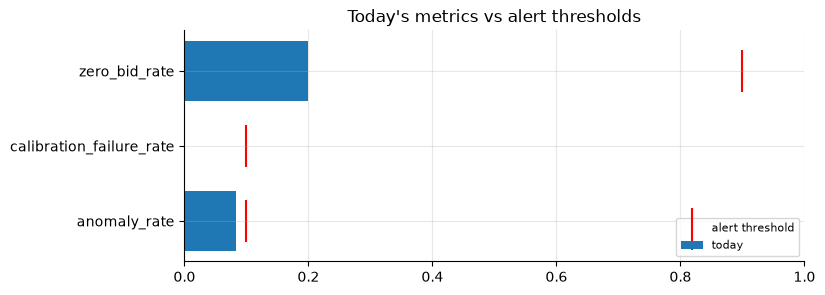

Alerts fired: none


In [21]:
from ivmon import alert, report

m = report.collect_metrics(con, SNAP, {}, [])
th = alert.default_thresholds()
rows = [("anomaly_rate", m["anomaly_rate"], th["anomaly_rate"]),
        ("calibration_failure_rate", m["calibration_failure_rate"], th["calibration_failure_rate"]),
        ("zero_bid_rate", m["zero_bid_rate"], th["zero_bid_rate"])]
mt = pd.DataFrame(rows, columns=["metric", "today", "alert_if_above"])
mt["status"] = np.where(mt["today"] > mt["alert_if_above"], "ALERT", "ok")
display(mt)

fig, ax = plt.subplots(figsize=(8, 3))
y = np.arange(len(mt))
ax.barh(y, mt["today"], color="tab:blue", label="today")
ax.scatter(mt["alert_if_above"], y, color="red", marker="|", s=900, label="alert threshold")
ax.set_yticks(y); ax.set_yticklabels(mt["metric"])
ax.set_xlim(0, 1)
ax.set_title("Today's metrics vs alert thresholds")
ax.legend(fontsize=8)
plt.show()

fired = alert.evaluate_alerts({**m, "ingest_rows": None})
print("Alerts fired:", [a.name for a in fired] or "none")

## Wrap-up

| Question | Answer from this notebook |
|---|---|
| Is the vendor data clean? | No: many zero-bid, wide and stale quotes, especially in thin names (section 2) |
| Can we rebuild IV ourselves? | Yes for most OTM quotes, with explicit reason codes when we can't (section 3) |
| Does a smooth surface fit? | About 1 vol point typical error (section 5) |
| What do the rules catch? | Arbitrage violations and outliers; strong on spikes, swaps, IV shifts (sections 6 and 8) |
| Does ML help? | Only marginally, mostly on strike typos (sections 7 and 8) |
| Does remediation improve the fit? | Not yet; the policy isn't validated (section 9) |

**Limitations to keep in mind:** snapshot-only free data, American options priced with a European model on OTM quotes, ETFs as commodity proxies, evaluation on self-injected errors, uncalibrated alert thresholds.

**Run it yourself:** `python -m ivmon.pipeline` (during US market hours) refreshes the database, then re-run this notebook.